In [1]:
# Required Libraries
import os
os.environ["SCIPY_ARRAY_API"] = "1"
import numpy as np 
import pandas as pd 
from scipy.stats import skew, kurtosis 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from imblearn.over_sampling import SMOTE 
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Loading the Data

In [2]:
df=pd.read_csv('../data/T-1_final_labeled.csv')
df=df.drop('Point Type',axis=1)

# 2. Preprocessing

In [3]:
# Checking for missing values
print(df.isnull().sum().sum())

0


In [4]:
# Feature Extraction
def extract_stat_features(df): 
    features=pd.DataFrame()
    features['mean']=df.mean(axis=1)
    features['std']=df.std(axis=1)
    features['var']=df.var(axis=1)
    features['min'] = df.min(axis=1)
    features['max'] = df.max(axis=1)
    features['ptp'] = df.max(axis=1) - df.min(axis=1)  # peak-to-peak
    
    features['rms'] = np.sqrt((df ** 2).mean(axis=1))
    features['skewness'] = df.apply(lambda row: skew(row), axis=1)
    features['kurtosis'] = df.apply(lambda row: kurtosis(row), axis=1)
    
    # First & second order differences (mean across the row)
    features['diff1'] = df.diff(axis=1).mean(axis=1)
    features['diff2'] = df.diff(periods=2, axis=1).mean(axis=1)

    return features

In [5]:
X=df.drop('Normal',axis=1)
y=df['Normal']

# 3. Feature Engineering

In [6]:
engineered=extract_stat_features(X)
engineered_df=pd.DataFrame(engineered)

# 4. Scaling

In [7]:
scaler=StandardScaler()
engineered_scaled=pd.DataFrame(scaler.fit_transform(engineered_df),columns=engineered_df.columns)

# 5. PCA

In [8]:
pca=PCA(n_components=0.95)
X_pca=pca.fit_transform(engineered_scaled)
pca_df=pd.DataFrame(X_pca,columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])

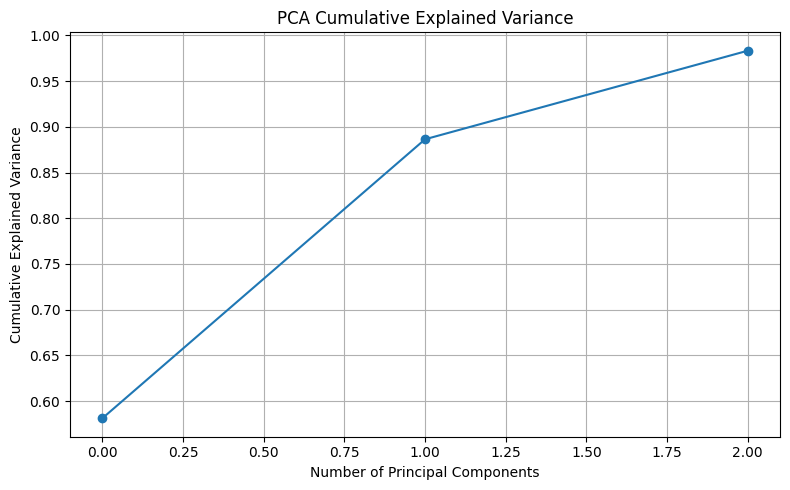

In [9]:
# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='-')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Train-Test Split

In [10]:
#Splitting the dataset 
X_train,X_test,y_train,y_test=train_test_split(pca_df,y,test_size=0.3,stratify=y,random_state=1)

# 7. SMOTE

In [11]:
sm=SMOTE(random_state=42)
X_resampled,y_resampled=sm.fit_resample(X_train,y_train)

# 8. Model Training

In [12]:
#Parameter Grid 
param_grid={
    'C':[1,10,100,120], 
    'gamma':[0.01,0.05,0.1,1]
}
model=SVC(kernel='rbf',class_weight='balanced')
grid=RandomizedSearchCV(model,param_grid,cv=5,scoring='recall',n_jobs=-1)
grid.fit(X_resampled,y_resampled)

RandomizedSearchCV(cv=5, estimator=SVC(class_weight='balanced'), n_jobs=-1,
                   param_distributions={'C': [1, 10, 100, 120],
                                        'gamma': [0.01, 0.05, 0.1, 1]},
                   scoring='recall')

In [13]:
#Best Parameters
print(f'Best Parameters:{grid.best_params_}')

Best Parameters:{'gamma': 0.01, 'C': 1}


# 9. Evaluation

In [14]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

# 10. Saving Outputs

In [15]:
#Classification Report  
target_names = ['Anomaly', 'Normal']
cr=classification_report(y_pred=y_pred,y_true=y_test,target_names=target_names)
print(cr)

              precision    recall  f1-score   support

     Anomaly       0.65      0.65      0.65       461
      Normal       0.92      0.92      0.92      2123

    accuracy                           0.88      2584
   macro avg       0.79      0.79      0.79      2584
weighted avg       0.88      0.88      0.88      2584



In [16]:
# Confusion Matrix
cm=confusion_matrix(y_test,y_pred=y_pred,labels=[-1,1])
cm

array([[ 299,  162],
       [ 160, 1963]])

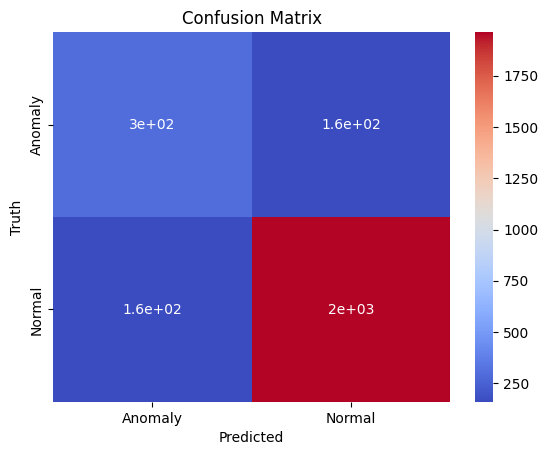

In [17]:
# Heat Map
sns.heatmap(cm,annot=True,cmap='coolwarm',xticklabels=['Anomaly','Normal'],yticklabels=['Anomaly','Normal'])
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('Confusion Matrix')
plt.show()